<a href="https://colab.research.google.com/github/678-shiv/ES-678-ML-Project/blob/main/Ml-Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving Mendeley_edited.xlsx to Mendeley_edited (2).xlsx
Train shape: (1356, 20)
Test  shape: (339, 20)


,b,h,Lo,B,d,fc,As1,As2,fy1,fy2,Es1,Es2,tf,bf,Af,Ef,ff,Anchor,Loading,Pu
count,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00,1356.00
mean,168.74,239.79,2232.59,948.19,207.62,33.07,349.33,165.22,413.43,396.50,203.29,203.89,0.71,130.95,89.96,178.62,2755.80,1.35,3.91,74.74
std,109.15,89.90,954.58,496.46,83.24,10.63,355.10,193.56,83.28,93.54,36.28,37.53,0.93,56.06,132.52,66.25,1193.28,0.48,0.29,77.63
min,76.00,100.00,812.00,300.00,84.00,7.83,33.00,14.10,242.20,212.20,2.00,2.00,0.00,24.46,0.00,6.27,40.76,1.00,3.00,6.58
25%,120.00,180.00,1600.00,600.00,150.00,25.10,157.00,57.00,355.40,324.00,200.00,200.00,0.17,96.90,22.20,135.93,1923.45,1.00,4.00,31.22
50%,150.00,250.00,2000.00,898.00,214.50,32.88,235.50,100.50,400.00,374.20,200.00,200.00,0.33,118.20,45.00,208.82,3325.00,1.00,4.00,53.96
75%,200.00,300.00,2600.00,1100.00,262.00,40.63,401.90,157.00,456.00,452.00,200.00,210.00,1.00,152.00,100.00,229.95,3550.00,2.00,4.00,88.78
max,960.00,600.00,6000.00,2998.00,548.00,54.80,2411.50,1607.70,611.00,611.00,500.00,500.00,9.56,368.00,1020.00,299.00,4900.00,2.00,4.00,669.30


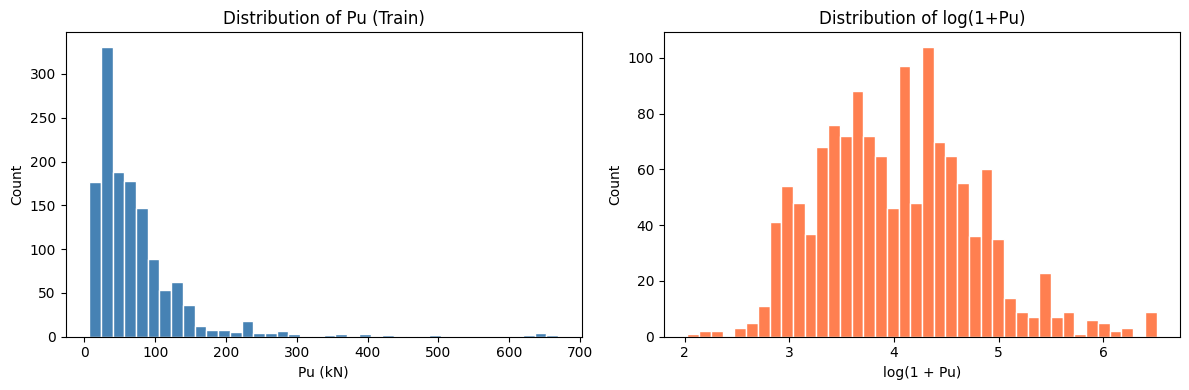

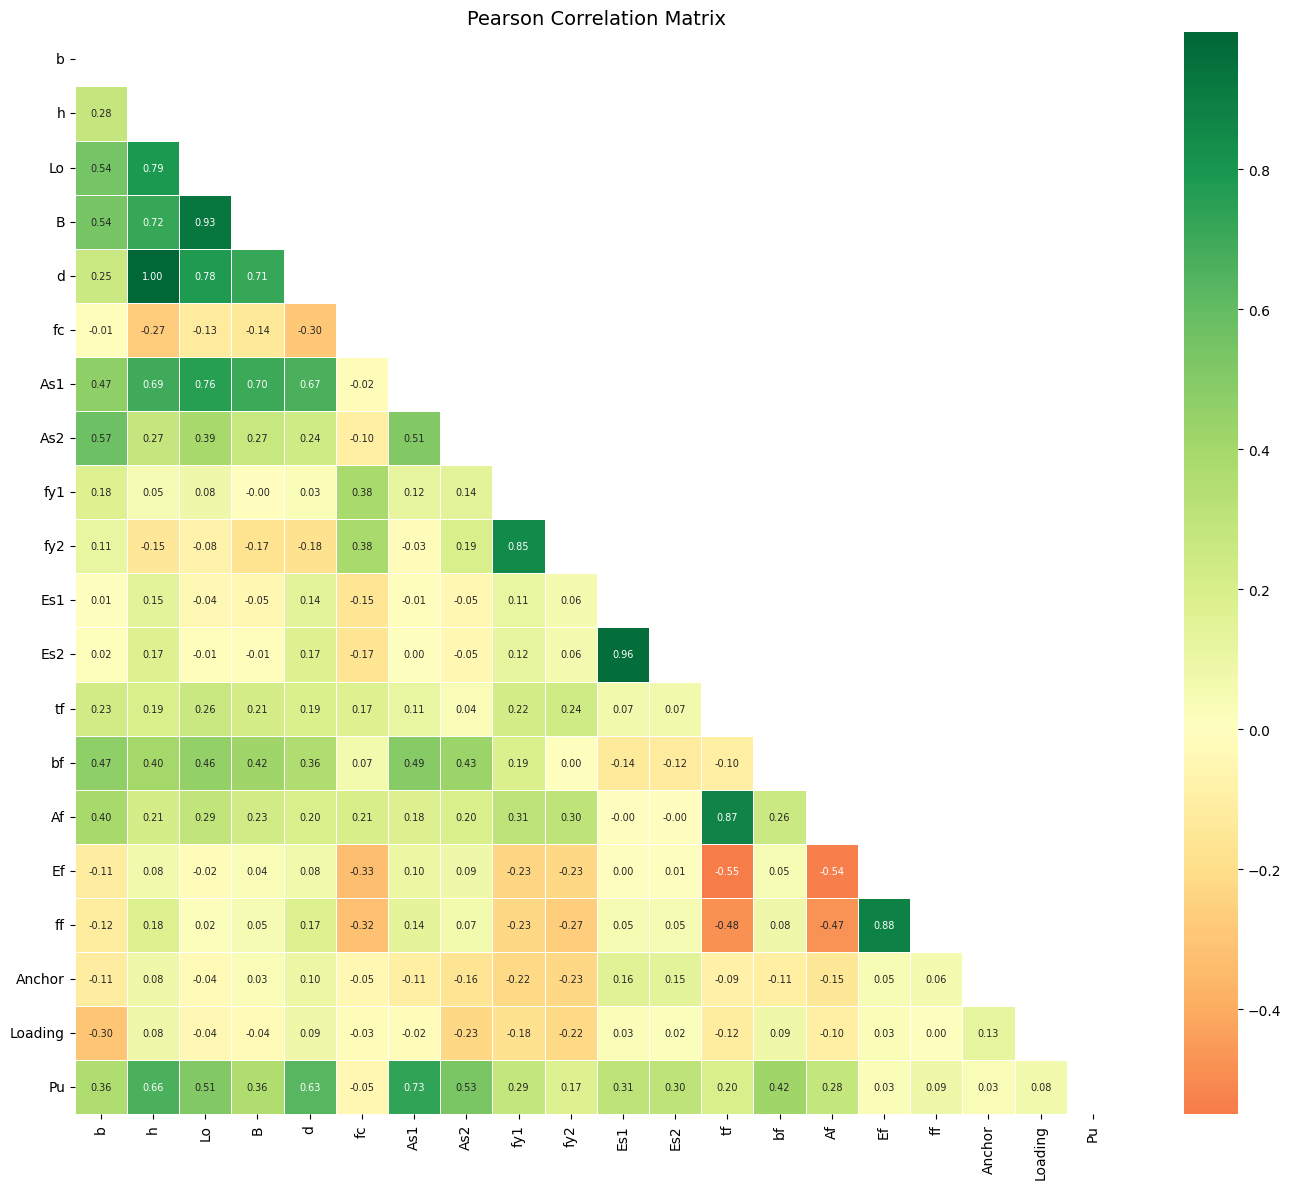


Feature correlations with Pu (absolute):
As1        0.734
h          0.661
d          0.630
As2        0.530
Lo         0.510
bf         0.415
B          0.364
b          0.363
Es1        0.307
Es2        0.303
fy1        0.289
Af         0.284
tf         0.202
fy2        0.174
ff         0.088
Loading    0.075
fc         0.053
Anchor     0.034
Ef         0.026


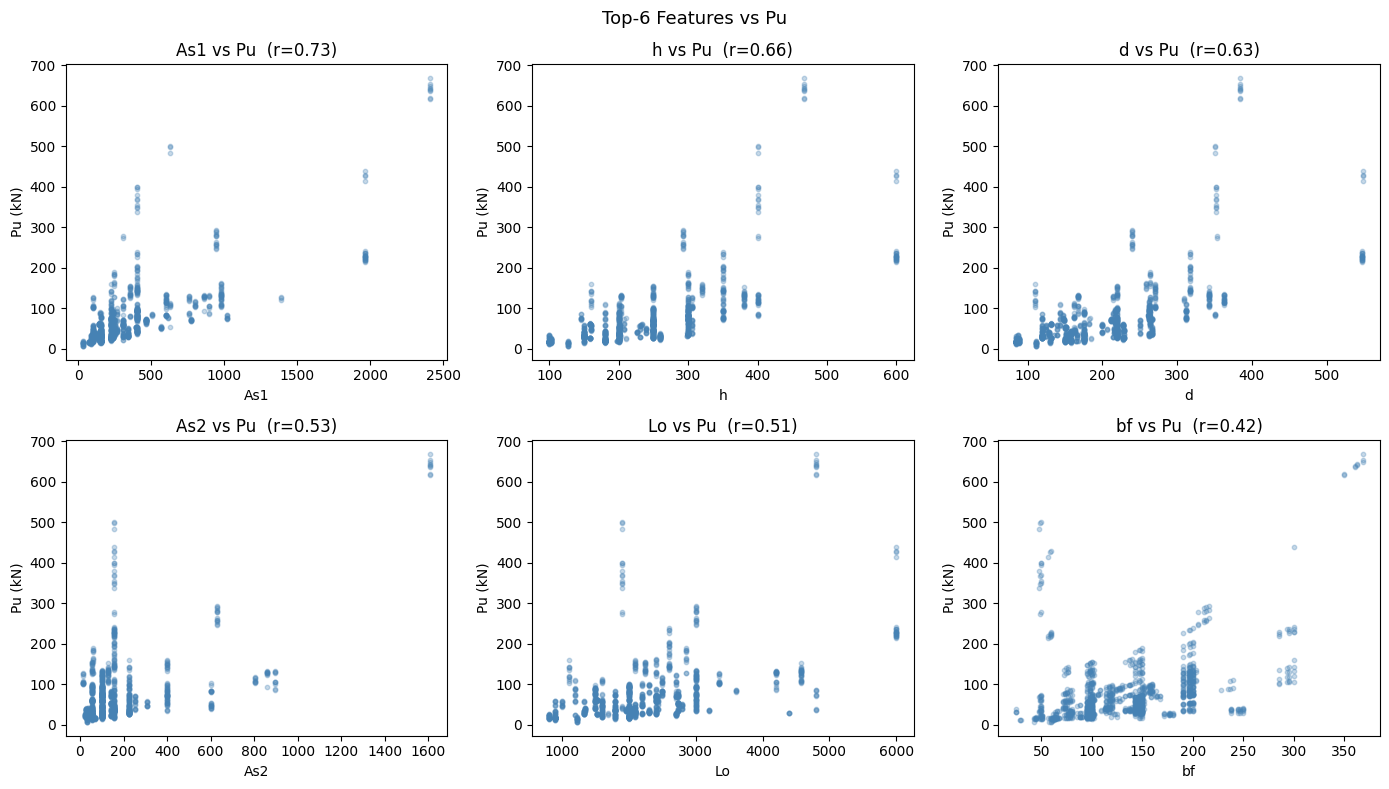

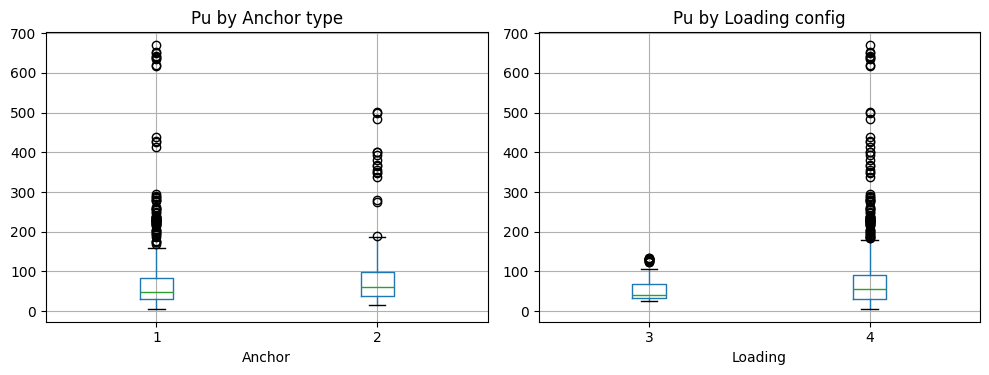

In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.svm import SVR
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import loguniform
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score


uploaded = files.upload()

df_train = pd.read_excel("Provided_Train_Test_Pu.xlsx", sheet_name="Train_Pu")
df_test  = pd.read_excel("Provided_Train_Test_Pu.xlsx", sheet_name="Test_Pu")
print("Train shape:", df_train.shape)
print("Test  shape:", df_test.shape)
display(df_train.describe().round(2))

FEATURES = ['b','h','Lo','B','d','fc','As1','As2','fy1','fy2',
            'Es1','Es2','tf','bf','Af','Ef','ff','Anchor','Loading']
TARGET = 'Pu'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_train[TARGET], bins=40, color='steelblue', edgecolor='white')
axes[0].set_title("Distribution of Pu (Train)")
axes[0].set_xlabel("Pu (kN)"); axes[0].set_ylabel("Count")
axes[1].hist(np.log1p(df_train[TARGET]), bins=40, color='coral', edgecolor='white')
axes[1].set_title("Distribution of log(1+Pu)")
axes[1].set_xlabel("log(1 + Pu)"); axes[1].set_ylabel("Count")
plt.tight_layout(); plt.show()

corr = df_train[FEATURES + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdYlGn",
            center=0, linewidths=0.4, ax=ax, annot_kws={"size": 7})
ax.set_title("Pearson Correlation Matrix", fontsize=14)
plt.tight_layout(); plt.show()

target_corr = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False)
print("\nFeature correlations with Pu (absolute):")
print(target_corr.round(3).to_string())

top6 = target_corr.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, feat in zip(axes.flatten(), top6):
    ax.scatter(df_train[feat], df_train[TARGET], alpha=0.3, s=10, color='steelblue')
    ax.set_xlabel(feat); ax.set_ylabel("Pu (kN)")
    ax.set_title(f"{feat} vs Pu  (r={corr.loc[feat, TARGET]:.2f})")
plt.suptitle("Top-6 Features vs Pu", fontsize=13)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df_train.boxplot(column=TARGET, by='Anchor',  ax=axes[0])
df_train.boxplot(column=TARGET, by='Loading', ax=axes[1])
axes[0].set_title("Pu by Anchor type")
axes[1].set_title("Pu by Loading config")
plt.suptitle(""); plt.tight_layout(); plt.show()

In [17]:


df_train = pd.read_excel("Provided_Train_Test_Pu.xlsx", sheet_name="Train_Pu")
df_test  = pd.read_excel("Provided_Train_Test_Pu.xlsx", sheet_name="Test_Pu")

TARGET = 'Pu'

y_train = df_train[TARGET].values
y_test  = df_test[TARGET].values

df_train['Anchor']  = df_train['Anchor'].astype(str)
df_train['Loading'] = df_train['Loading'].astype(str)
df_test['Anchor']   = df_test['Anchor'].astype(str)
df_test['Loading']  = df_test['Loading'].astype(str)

combined = pd.concat([df_train, df_test], keys=['train','test'])
combined = pd.get_dummies(combined, columns=['Anchor','Loading'], drop_first=False)
df_train_enc = combined.loc['train'].drop(columns=[TARGET])
df_test_enc  = combined.loc['test'].drop(columns=[TARGET])

feature_names = list(df_train_enc.columns)
X_train = df_train_enc.values.astype(float)
X_test  = df_test_enc.values.astype(float)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)   # transform only, no leakage

print("Features:", feature_names)
print(f"\nX_train_sc : {X_train_sc.shape}")
print(f"X_test_sc  : {X_test_sc.shape}")
print(f"y_train    : mean={y_train.mean():.2f}, std={y_train.std():.2f}")
print(f"y_test     : mean={y_test.mean():.2f},  std={y_test.std():.2f}")
print("\nPreprocessing done ")

Features: ['b', 'h', 'Lo', 'B', 'd', 'fc', 'As1', 'As2', 'fy1', 'fy2', 'Es1', 'Es2', 'tf', 'bf', 'Af', 'Ef', 'ff', 'Anchor_1', 'Anchor_2', 'Loading_3', 'Loading_4']

X_train_sc : (1356, 21)
X_test_sc  : (339, 21)
y_train    : mean=74.74, std=77.60
y_test     : mean=69.67,  std=62.94

Preprocessing done 


── Linear Regression (Baseline) ──────────────────────
Train      → R²=0.8480  RMSE=30.254 kN  MAE=22.261 kN  MAPE=44.01%
Test       → R²=0.7804  RMSE=29.497 kN  MAE=21.691 kN  MAPE=43.32%


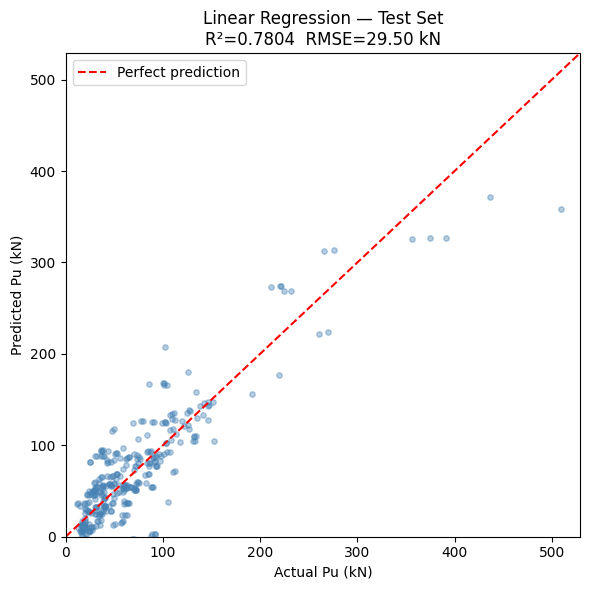


Baseline done  — note these numbers, RF and SVR must beat them!


In [18]:



lr = LinearRegression()
lr.fit(X_train_sc, y_train)

y_train_pred_lr = lr.predict(X_train_sc)
y_test_pred_lr  = lr.predict(X_test_sc)

def get_metrics(y_true, y_pred, label):
    r2   = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-8))) * 100
    print(f"{label:10s} → R²={r2:.4f}  RMSE={rmse:.3f} kN  MAE={mae:.3f} kN  MAPE={mape:.2f}%")
    return dict(R2=r2, RMSE=rmse, MAE=mae, MAPE=mape)

print("── Linear Regression (Baseline) ──────────────────────")
lr_train_m = get_metrics(y_train, y_train_pred_lr, "Train")
lr_test_m  = get_metrics(y_test,  y_test_pred_lr,  "Test")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_test_pred_lr, alpha=0.4, s=15, color='steelblue')
lims = [0, max(y_test.max(), y_test_pred_lr.max()) + 20]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual Pu (kN)")
ax.set_ylabel("Predicted Pu (kN)")
ax.set_title(f"Linear Regression — Test Set\nR²={lr_test_m['R2']:.4f}  RMSE={lr_test_m['RMSE']:.2f} kN")
ax.legend(); plt.tight_layout(); plt.show()

print("\nBaseline done  — note these numbers, RF and SVR must beat them!")

Running GridSearchCV... (takes 3–5 min) 
Fitting 5 folds for each of 72 candidates, totalling 360 fits

Best params : {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 500}
Best CV R²  : 0.9738

── Random Forest ─────────────────────────────────────
Train      → R²=0.9964  RMSE=4.673 kN  MAE=2.496 kN  MAPE=3.61%
Test       → R²=0.9726  RMSE=10.424 kN  MAE=5.708 kN  MAPE=8.70%


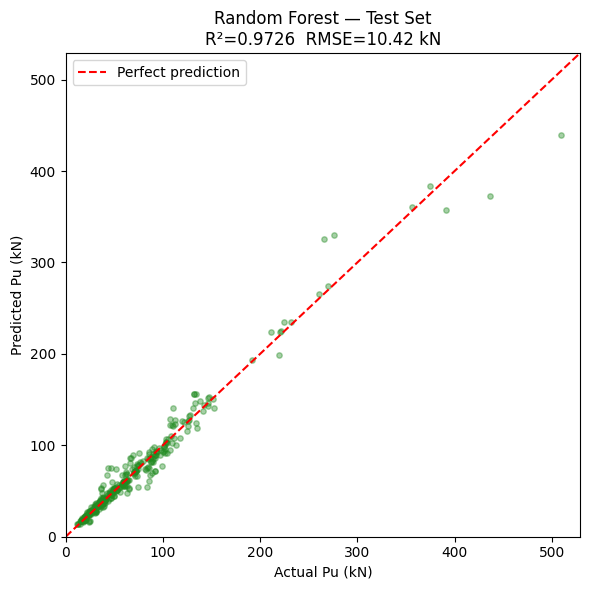

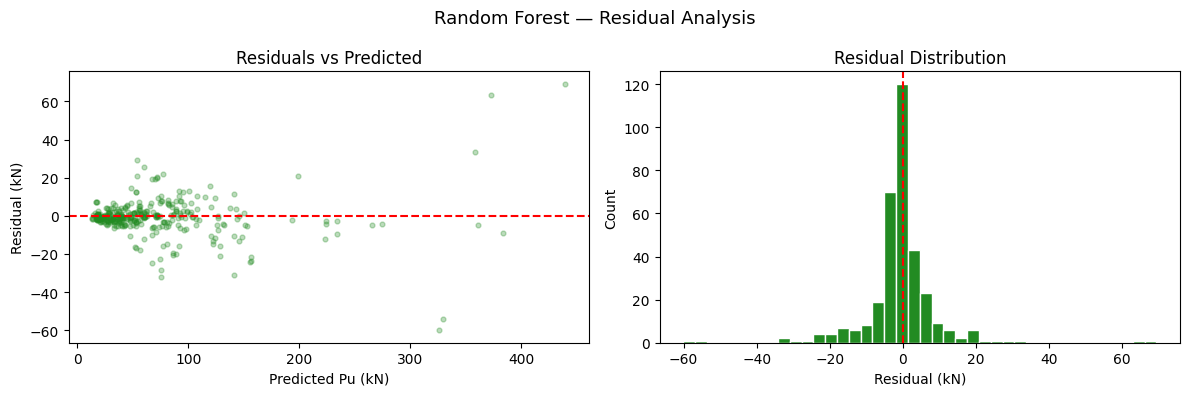

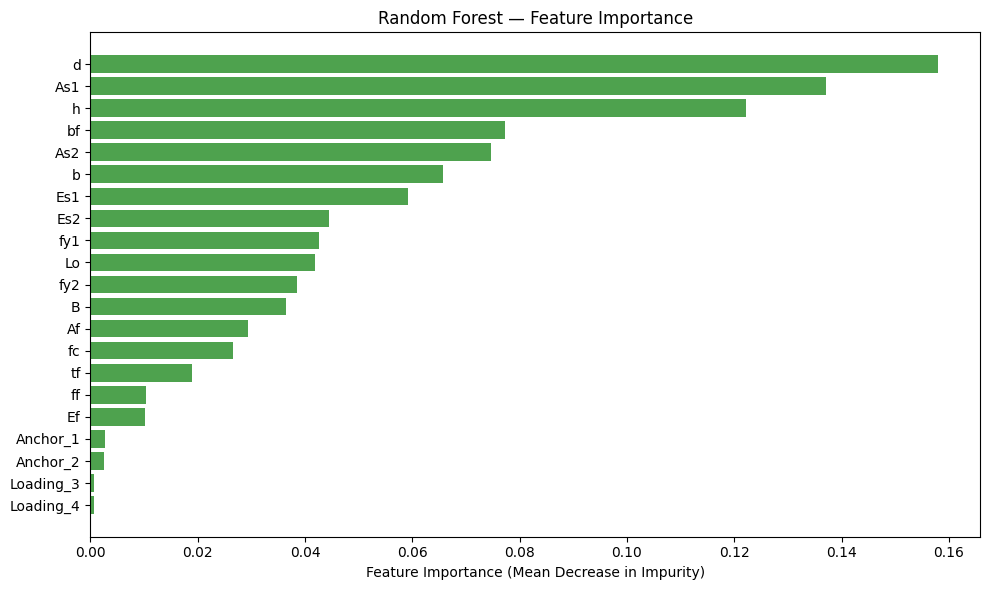


Random Forest done 


In [19]:

param_grid = {
    'n_estimators':      [100, 300, 500],
    'max_depth':         [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'max_features':      ['sqrt', 'log2'],
}

print("Running GridSearchCV... (takes 3–5 min) ")
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)
grid_search = GridSearchCV(rf_base, param_grid, cv=5,
                           scoring='r2', n_jobs=-1, verbose=1, refit=True)
grid_search.fit(X_train_sc, y_train)

best_rf = grid_search.best_estimator_
print(f"\nBest params : {grid_search.best_params_}")
print(f"Best CV R²  : {grid_search.best_score_:.4f}")

y_train_pred_rf = best_rf.predict(X_train_sc)
y_test_pred_rf  = best_rf.predict(X_test_sc)

print("\n── Random Forest ─────────────────────────────────────")
rf_train_m = get_metrics(y_train, y_train_pred_rf, "Train")
rf_test_m  = get_metrics(y_test,  y_test_pred_rf,  "Test")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_test_pred_rf, alpha=0.4, s=15, color='forestgreen')
lims = [0, max(y_test.max(), y_test_pred_rf.max()) + 20]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual Pu (kN)")
ax.set_ylabel("Predicted Pu (kN)")
ax.set_title(f"Random Forest — Test Set\nR²={rf_test_m['R2']:.4f}  RMSE={rf_test_m['RMSE']:.2f} kN")
ax.legend(); plt.tight_layout(); plt.show()

residuals_rf = y_test - y_test_pred_rf
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test_pred_rf, residuals_rf, alpha=0.3, s=12, color='forestgreen')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Pu (kN)"); axes[0].set_ylabel("Residual (kN)")
axes[0].set_title("Residuals vs Predicted")
axes[1].hist(residuals_rf, bins=40, color='forestgreen', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_xlabel("Residual (kN)"); axes[1].set_ylabel("Count")
axes[1].set_title("Residual Distribution")
plt.suptitle("Random Forest — Residual Analysis", fontsize=13)
plt.tight_layout(); plt.show()

importances = best_rf.feature_importances_
indices     = np.argsort(importances)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh([feature_names[i] for i in indices], importances[indices],
        color='forestgreen', alpha=0.8)
ax.set_xlabel("Feature Importance (Mean Decrease in Impurity)")
ax.set_title("Random Forest — Feature Importance")
plt.tight_layout(); plt.show()

print("\nRandom Forest done ")

Running RandomizedSearchCV for SVR... (takes 5–8 min) 
Fitting 5 folds for each of 60 candidates, totalling 300 fits

Best params : {'C': np.float64(876.1971101023682), 'degree': 3, 'epsilon': np.float64(0.5999156225282403), 'gamma': 'scale', 'kernel': 'rbf'}
Best CV R²  : 0.9825

── Support Vector Regression ─────────────────────────
Train      → R²=0.9935  RMSE=6.264 kN  MAE=2.864 kN  MAPE=4.87%
Test       → R²=0.9822  RMSE=8.392 kN  MAE=4.113 kN  MAPE=6.91%


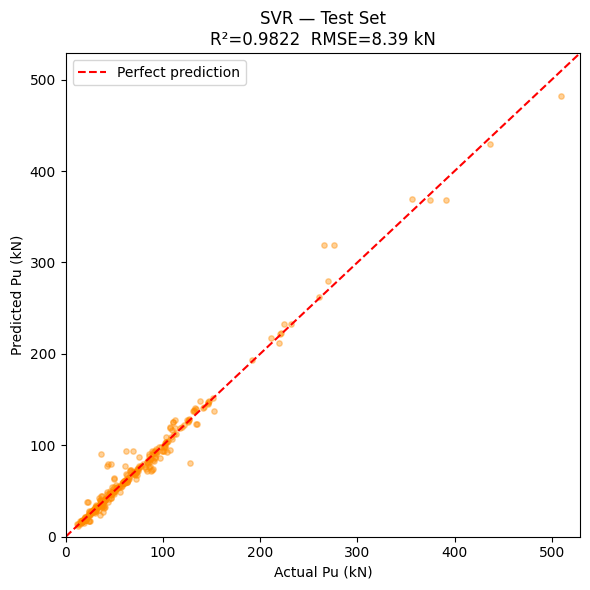

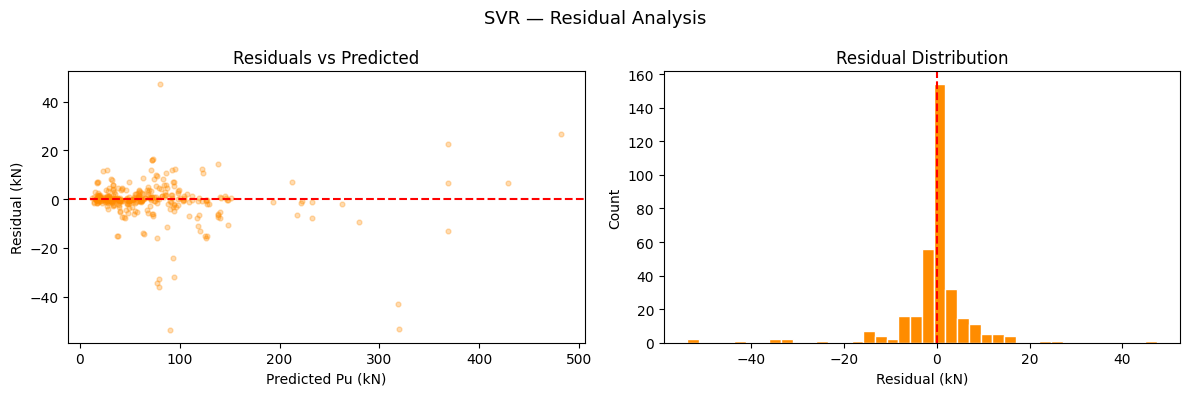


SVR done 


In [20]:


param_dist = {
    'kernel':  ['rbf', 'poly'],
    'C':       loguniform(0.1, 1000),
    'epsilon': loguniform(0.01, 10),
    'gamma':   ['scale', 'auto'],
    'degree':  [2, 3],
}

print("Running RandomizedSearchCV for SVR... (takes 5–8 min) ")
svr_base = SVR()
rand_search = RandomizedSearchCV(svr_base, param_distributions=param_dist,
                                  n_iter=60, cv=5, scoring='r2',
                                  n_jobs=-1, verbose=1, random_state=42,
                                  refit=True)
rand_search.fit(X_train_sc, y_train)

best_svr = rand_search.best_estimator_
print(f"\nBest params : {rand_search.best_params_}")
print(f"Best CV R²  : {rand_search.best_score_:.4f}")

y_train_pred_svr = best_svr.predict(X_train_sc)
y_test_pred_svr  = best_svr.predict(X_test_sc)

print("\n── Support Vector Regression ─────────────────────────")
svr_train_m = get_metrics(y_train, y_train_pred_svr, "Train")
svr_test_m  = get_metrics(y_test,  y_test_pred_svr,  "Test")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_test_pred_svr, alpha=0.4, s=15, color='darkorange')
lims = [0, max(y_test.max(), y_test_pred_svr.max()) + 20]
ax.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual Pu (kN)")
ax.set_ylabel("Predicted Pu (kN)")
ax.set_title(f"SVR — Test Set\nR²={svr_test_m['R2']:.4f}  RMSE={svr_test_m['RMSE']:.2f} kN")
ax.legend(); plt.tight_layout(); plt.show()

residuals_svr = y_test - y_test_pred_svr
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_test_pred_svr, residuals_svr, alpha=0.3, s=12, color='darkorange')
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel("Predicted Pu (kN)"); axes[0].set_ylabel("Residual (kN)")
axes[0].set_title("Residuals vs Predicted")
axes[1].hist(residuals_svr, bins=40, color='darkorange', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_xlabel("Residual (kN)"); axes[1].set_ylabel("Count")
axes[1].set_title("Residual Distribution")
plt.suptitle("SVR — Residual Analysis", fontsize=13)
plt.tight_layout(); plt.show()

print("\nSVR done ")

── Model Comparison (Test Set) ────────────────────────


,Model,R²,RMSE (kN),MAE (kN),MAPE (%)
0,Linear Regression (Baseline),0.7804,29.4971,21.6910,43.3176
1,Random Forest,0.9726,10.4236,5.7084,8.6962
2,SVR,0.9822,8.3924,4.1125,6.9058


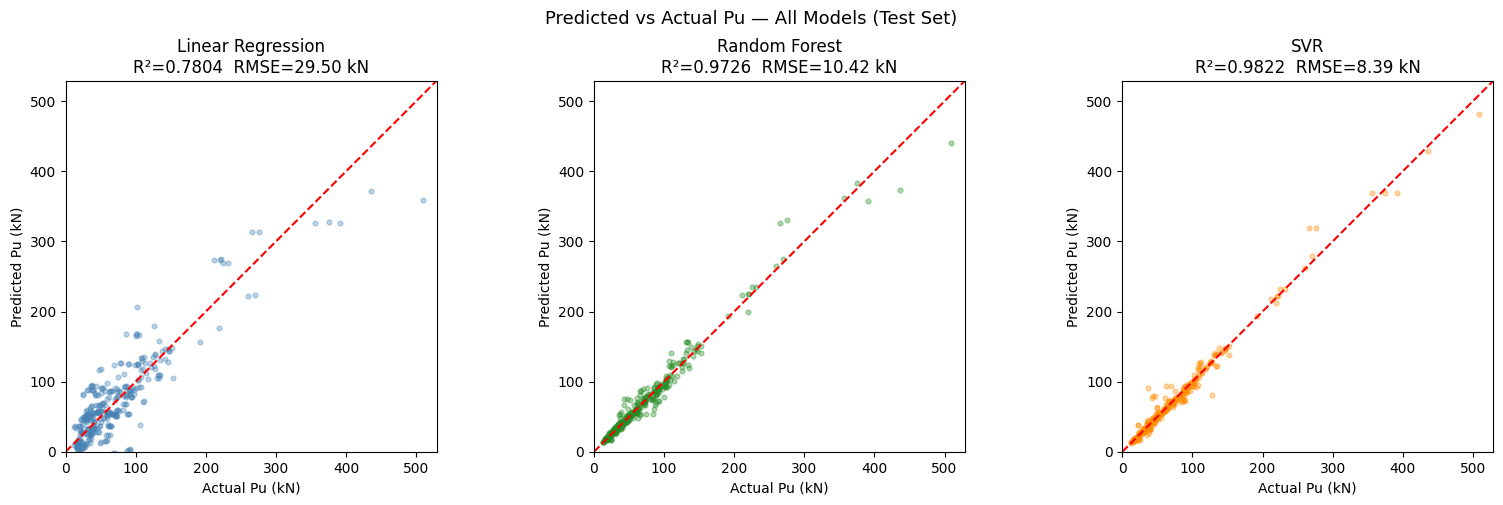

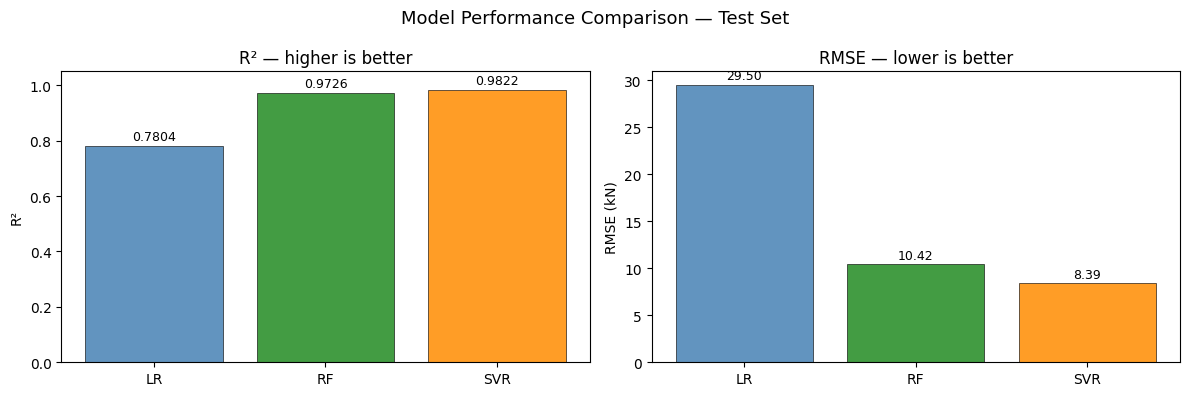


── Top-10 Largest Errors (Random Forest) ─────────────
  #      Actual   Predicted   Abs Error   % Error
  1      509.00      439.69       69.31     13.6%
  2      436.00      372.62       63.38     14.5%
  3      266.00      326.09       60.09     22.6%
  4      275.80      329.84       54.04     19.6%
  5      391.40      357.93       33.47      8.6%
  6       43.20       75.18       31.98     74.0%
  7      110.00      141.21       31.21     28.4%
  8       83.50       54.04       29.46     35.3%
  9       46.60       75.18       28.58     61.3%
 10       86.01       60.52       25.49     29.6%

Comparison done


In [21]:

results = pd.DataFrame({
    'Model':      ['Linear Regression (Baseline)', 'Random Forest', 'SVR'],
    'R²':         [lr_test_m['R2'],   rf_test_m['R2'],   svr_test_m['R2']],
    'RMSE (kN)':  [lr_test_m['RMSE'], rf_test_m['RMSE'], svr_test_m['RMSE']],
    'MAE (kN)':   [lr_test_m['MAE'],  rf_test_m['MAE'],  svr_test_m['MAE']],
    'MAPE (%)':   [lr_test_m['MAPE'], rf_test_m['MAPE'], svr_test_m['MAPE']],
})
print("── Model Comparison (Test Set) ────────────────────────")
display(results.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
configs = [
    (y_test_pred_lr,  lr_test_m,  'Linear Regression', 'steelblue'),
    (y_test_pred_rf,  rf_test_m,  'Random Forest',     'forestgreen'),
    (y_test_pred_svr, svr_test_m, 'SVR',               'darkorange'),
]
for ax, (y_pred, m, name, color) in zip(axes, configs):
    ax.scatter(y_test, y_pred, alpha=0.35, s=12, color=color)
    lims = [0, max(y_test.max(), y_pred.max()) + 20]
    ax.plot(lims, lims, 'r--', linewidth=1.5)
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel("Actual Pu (kN)"); ax.set_ylabel("Predicted Pu (kN)")
    ax.set_title(f"{name}\nR²={m['R2']:.4f}  RMSE={m['RMSE']:.2f} kN")
    ax.set_aspect('equal')
plt.suptitle("Predicted vs Actual Pu — All Models (Test Set)", fontsize=13)
plt.tight_layout(); plt.show()

labels = ['LR', 'RF', 'SVR']
colors = ['steelblue', 'forestgreen', 'darkorange']
x = np.arange(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

r2_vals   = [lr_test_m['R2'],   rf_test_m['R2'],   svr_test_m['R2']]
rmse_vals = [lr_test_m['RMSE'], rf_test_m['RMSE'], svr_test_m['RMSE']]

bars0 = axes[0].bar(x, r2_vals, color=colors, alpha=0.85, edgecolor='k', linewidth=0.5)
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylabel("R²"); axes[0].set_title("R² — higher is better")
axes[0].set_ylim(0, 1.05)
for bar, val in zip(bars0, r2_vals):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{val:.4f}', ha='center', va='bottom', fontsize=9)

bars1 = axes[1].bar(x, rmse_vals, color=colors, alpha=0.85, edgecolor='k', linewidth=0.5)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels)
axes[1].set_ylabel("RMSE (kN)"); axes[1].set_title("RMSE — lower is better")
for bar, val in zip(bars1, rmse_vals):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.2f}', ha='center', va='bottom', fontsize=9)

plt.suptitle("Model Performance Comparison — Test Set", fontsize=13)
plt.tight_layout(); plt.show()

print("\n── Top-10 Largest Errors (Random Forest) ─────────────")
abs_err  = np.abs(y_test - y_test_pred_rf)
worst_idx = np.argsort(abs_err)[::-1][:10]
print(f"{'#':>3}  {'Actual':>10}  {'Predicted':>10}  {'Abs Error':>10}  {'% Error':>8}")
for rank, i in enumerate(worst_idx, 1):
    pct = abs_err[i] / (y_test[i] + 1e-8) * 100
    print(f"{rank:>3}  {y_test[i]:>10.2f}  {y_test_pred_rf[i]:>10.2f}"
          f"  {abs_err[i]:>10.2f}  {pct:>7.1f}%")

print("\nComparison done")

Computing permutation importance... (1–2 min) 


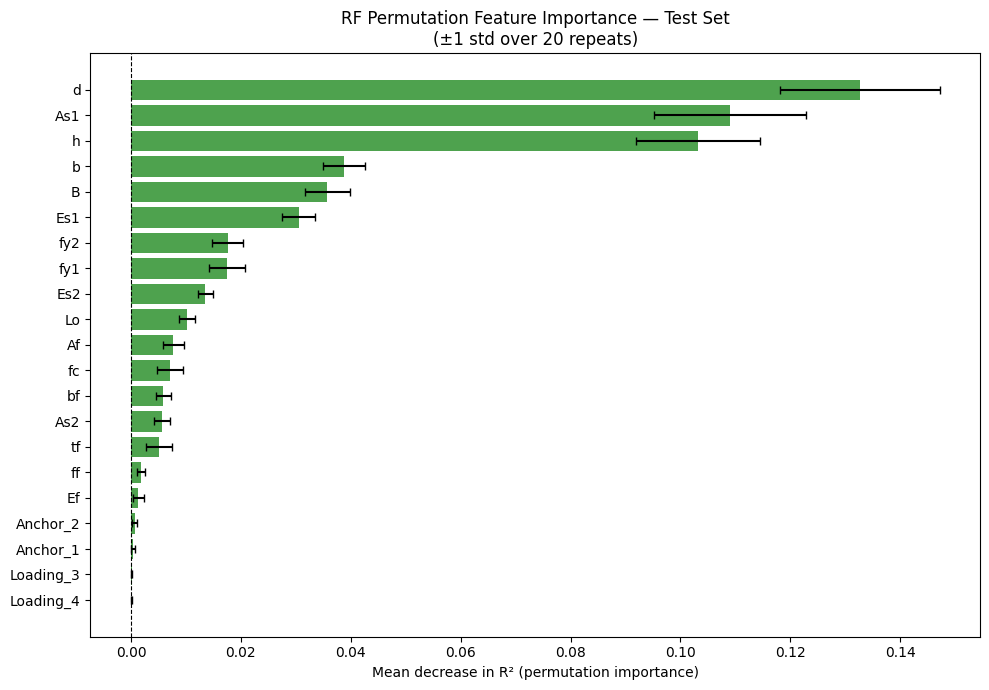


Top-5 features (permutation importance):
  d              : 0.1327 ± 0.0145
  As1            : 0.1090 ± 0.0138
  h              : 0.1032 ± 0.0112
  b              : 0.0387 ± 0.0038
  B              : 0.0357 ± 0.0041

Comparing SVR kernels via 5-fold CV... 
  rbf     : mean R² = 0.9825 ± 0.0085
  poly    : mean R² = 0.9828 ± 0.0054
  linear  : mean R² = 0.7461 ± 0.0216


/tmp/ipykernel_552/1741520102.py:37: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([kernel_scores[k] for k in kernels], labels=kernels,


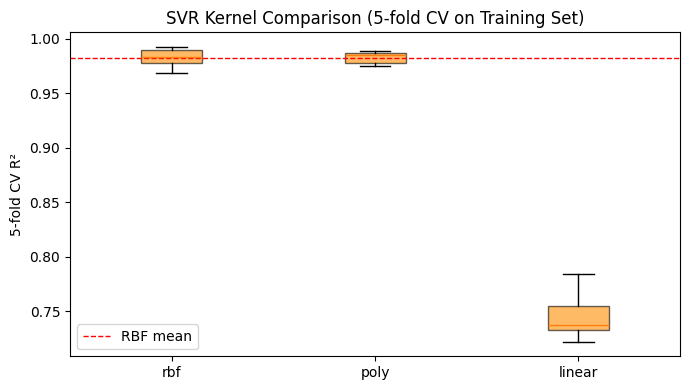


RF sensitivity to n_estimators... 
  n=  10: R²=0.9697 ± 0.0174
  n=  25: R²=0.9728 ± 0.0160
  n=  50: R²=0.9720 ± 0.0168
  n= 100: R²=0.9731 ± 0.0162
  n= 150: R²=0.9724 ± 0.0168
  n= 200: R²=0.9732 ± 0.0167
  n= 300: R²=0.9733 ± 0.0166
  n= 500: R²=0.9738 ± 0.0163


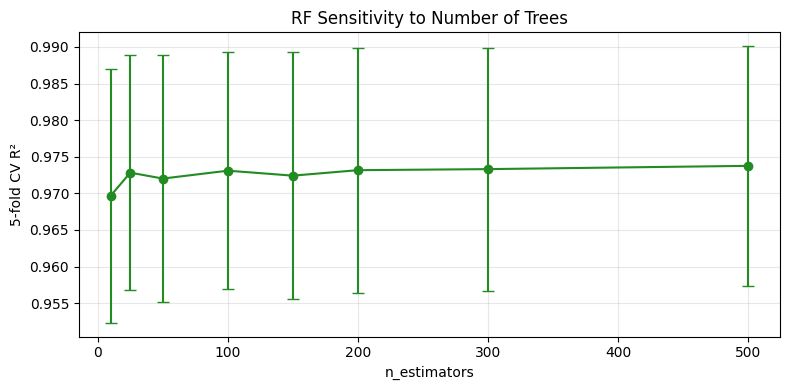

In [22]:

print("Computing permutation importance... (1–2 min) ")
perm = permutation_importance(best_rf, X_test_sc, y_test,
                               n_repeats=20, random_state=42, n_jobs=-1)

sorted_idx = np.argsort(perm.importances_mean)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(
    [feature_names[i] for i in sorted_idx],
    perm.importances_mean[sorted_idx],
    xerr=perm.importances_std[sorted_idx],
    color='forestgreen', alpha=0.8, capsize=3
)
ax.axvline(0, color='k', linestyle='--', linewidth=0.8)
ax.set_xlabel("Mean decrease in R² (permutation importance)")
ax.set_title("RF Permutation Feature Importance — Test Set\n(±1 std over 20 repeats)")
plt.tight_layout(); plt.show()

print("\nTop-5 features (permutation importance):")
for i in sorted_idx[::-1][:5]:
    print(f"  {feature_names[i]:15s}: {perm.importances_mean[i]:.4f} ± {perm.importances_std[i]:.4f}")

print("\nComparing SVR kernels via 5-fold CV... ")
kernels = ['rbf', 'poly', 'linear']
kernel_scores = {}
base_params = best_svr.get_params()

for k in kernels:
    p = {kk: vv for kk, vv in base_params.items()}
    p['kernel'] = k
    model_k = SVR(**p)
    scores = cross_val_score(model_k, X_train_sc, y_train,
                              cv=5, scoring='r2', n_jobs=-1)
    kernel_scores[k] = scores
    print(f"  {k:8s}: mean R² = {scores.mean():.4f} ± {scores.std():.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([kernel_scores[k] for k in kernels], labels=kernels,
           patch_artist=True,
           boxprops=dict(facecolor='darkorange', alpha=0.6))
ax.set_ylabel("5-fold CV R²")
ax.set_title("SVR Kernel Comparison (5-fold CV on Training Set)")
ax.axhline(kernel_scores['rbf'].mean(), color='red', linestyle='--',
           linewidth=1, label='RBF mean')
ax.legend(); plt.tight_layout(); plt.show()

print("\nRF sensitivity to n_estimators... ")
n_vals = [10, 25, 50, 100, 150, 200, 300, 500]
cv_means, cv_stds = [], []
best_rf_params = best_rf.get_params()

for n in n_vals:
    p = {kk: vv for kk, vv in best_rf_params.items()}
    p['n_estimators'] = n
    model_n = RandomForestRegressor(**p)
    scores = cross_val_score(model_n, X_train_sc, y_train,
                              cv=5, scoring='r2', n_jobs=-1)
    cv_means.append(scores.mean())
    cv_stds.append(scores.std())
    print(f"  n={n:4d}: R²={scores.mean():.4f} ± {scores.std():.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(n_vals, cv_means, yerr=cv_stds, marker='o',
            color='forestgreen', capsize=4, linewidth=1.5)
ax.set_xlabel("n_estimators")
ax.set_ylabel("5-fold CV R²")
ax.set_title("RF Sensitivity to Number of Trees")
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
